# Statistics and Probability


In [1]:
import math
import random
import statistics as st
import matplotlib.pyplot as plt
import numpy as np

# Plot style
plt.style.use('seaborn-v0_8-whitegrid')


## 1. Statistics

We start by describing a dataset and observing how an extreme value can change the reading of the process.


In [2]:
times = [9.8, 10.1, 10.0, 9.9, 10.2, 10.1, 9.7, 15.4]
times_no_outlier = [x for x in times if x < 12] # Example of list comprehension

def numeric_summary(data):
    sorted_data = sorted(data)
    q1, q2, q3 = np.percentile(sorted_data, [25, 50, 75])
    return {
        'mean': st.mean(data),
        'median': st.median(data),
        'q1': q1,
        'q3': q3,
        'std_dev': st.stdev(data),
        'data_range': max(data) - min(data),
        'iqr': q3 - q1,
    }

print('With outlier:', numeric_summary(times))
print('Without outlier:', numeric_summary(times_no_outlier))


With outlier: {'mean': 10.65, 'median': 10.05, 'q1': np.float64(9.875), 'q3': np.float64(10.125), 'std_dev': 1.926506831399404, 'data_range': 5.700000000000001, 'iqr': np.float64(0.25)}
Without outlier: {'mean': 9.971428571428572, 'median': 10.0, 'q1': np.float64(9.850000000000001), 'q3': np.float64(10.1), 'std_dev': 0.1799470821684873, 'data_range': 0.5, 'iqr': np.float64(0.24999999999999822)}


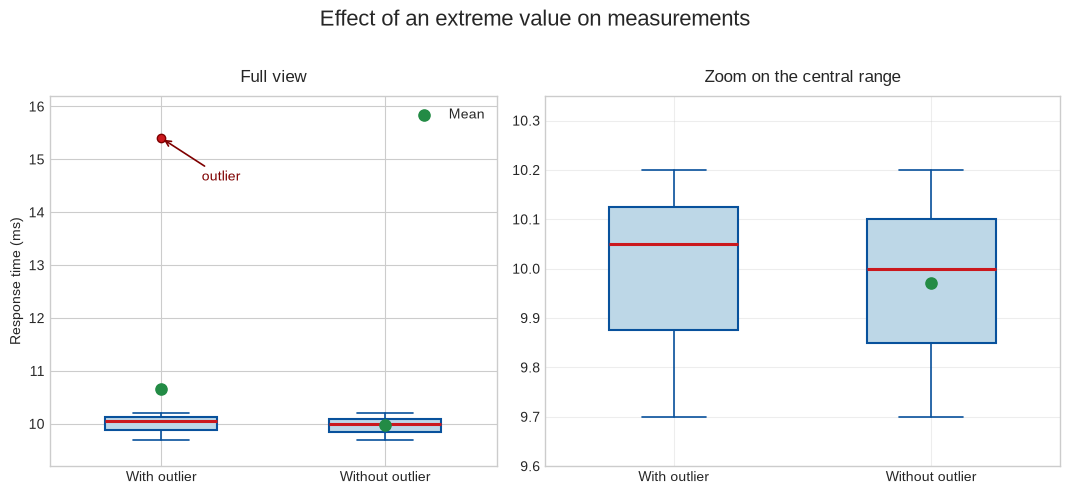

In [3]:
# Adjusting the figure to fit the slides format
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8), gridspec_kw={'width_ratios': [1.0, 1.15]})
style = dict(
    tick_labels=['With outlier', 'Without outlier'],
    patch_artist=True,
    widths=0.5,
    boxprops=dict(facecolor='#bdd7e7', edgecolor='#08519c', linewidth=1.5),
    medianprops=dict(color='#cb181d', linewidth=2.2),
    whiskerprops=dict(color='#08519c', linewidth=1.2),
    capprops=dict(color='#08519c', linewidth=1.2),
    flierprops=dict(marker='o', markerfacecolor='#cb181d', markeredgecolor='#7f0000', markersize=6),
)

# Mean values
means = [np.mean(times), np.mean(times_no_outlier)]

# Box plot with subplot
axes[0].boxplot([times, times_no_outlier], **style)
axes[0].scatter([1, 2], means, color='#238b45', s=65, zorder=3, label='Mean')
axes[0].annotate('outlier', xy=(1, 15.4), xytext=(1.18, 14.6),
                 arrowprops=dict(arrowstyle='->', color='#7f0000', lw=1.2), color='#7f0000')
axes[0].set_title('Full view', pad=10)
axes[0].set_ylabel('Response time (ms)')
axes[0].set_ylim(9.2, 16.2)
axes[0].margins(x=0.22)
axes[0].legend(frameon=False, loc='upper right')

axes[1].boxplot([times, times_no_outlier], showfliers=False, **{k: v for k, v in style.items() if k != 'flierprops'})
axes[1].scatter([1, 2], means, color='#238b45', s=65, zorder=3)
axes[1].set_title('Zoom on the central range', pad=10)
axes[1].set_ylim(9.6, 10.35)
axes[1].margins(x=0.22)
axes[1].grid(alpha=0.35)

fig.suptitle('Effect of an extreme value on measurements', fontsize=16, y=1.02)
fig.tight_layout()
plt.show()


### How to interpret the boxplot

In the boxplot, the line inside the box represents the median. The bottom and top of the box are, respectively, \(Q_1\) and \(Q_3\), the quartiles that delimit the central 50% of the data. The height of the box is the interquartile range, that is, \(IQR = Q_3 - Q_1\). The whiskers show the extent of the non-extreme values, and points far away appear as possible *outliers*.

In this example, the zoomed panel helps to see the central range better, which would be compressed if we showed only the full scale with the extreme value.


### Correlation

Now we contrast three situations: positive correlation, negative correlation, and a strong relationship that is not linear.


In [4]:
power = np.array([20, 25, 30, 35, 40, 45])
temperature = np.array([41, 44, 47, 53, 55, 58])
distance = np.array([1, 2, 3, 4, 5, 6])
signal = np.array([90, 84, 77, 70, 65, 58])
x = np.array([-3, -2, -1, 1, 2, 3])
y = x**2

print('Positive correlation:', round(np.corrcoef(power, temperature)[0, 1], 4))
print('Negative correlation:', round(np.corrcoef(distance, signal)[0, 1], 4))
print('Correlation in the nonlinear case y = x^2:', round(np.corrcoef(x, y)[0, 1], 4))


Positive correlation: 0.9917
Negative correlation: -0.9992
Correlation in the nonlinear case y = x^2: -0.0


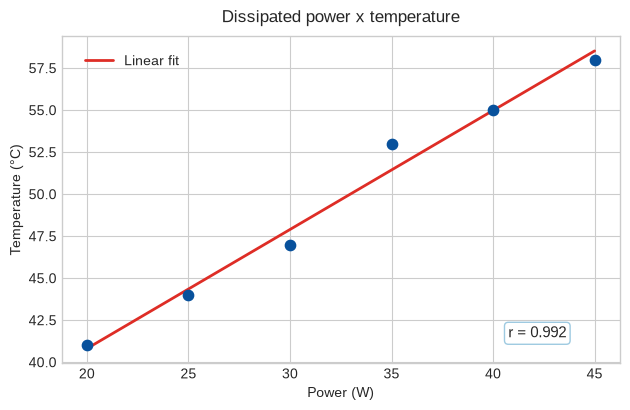

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter(power, temperature, color='#08519c', s=55, zorder=3)
coef = np.polyfit(power, temperature, 1)
x_line = np.linspace(power.min(), power.max(), 100)
ax.plot(x_line, coef[0] * x_line + coef[1], color='#de2d26', linewidth=2.0, label='Linear fit')
ax.text(0.80, 0.08, f'r = {np.corrcoef(power, temperature)[0, 1]:.3f}', transform=ax.transAxes,
        fontsize=11, bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#9ecae1'))
ax.set_title('Dissipated power x temperature', pad=10)
ax.set_xlabel('Power (W)')
ax.set_ylabel('Temperature (°C)')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(0.02, 0.98))
fig.tight_layout()
plt.show()


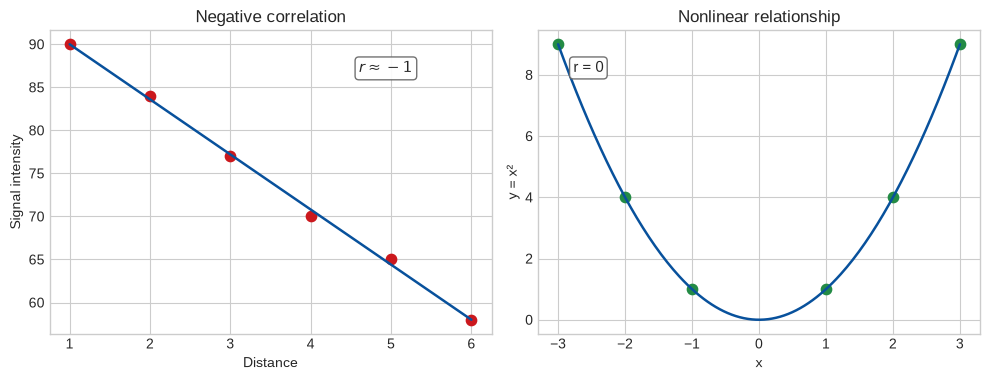

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.9))

axes[0].scatter(distance, signal, color='#cb181d', s=55)
coef_neg = np.polyfit(distance, signal, 1)
x_neg = np.linspace(distance.min(), distance.max(), 100)
axes[0].plot(x_neg, coef_neg[0] * x_neg + coef_neg[1], color='#08519c', linewidth=1.8)
axes[0].set_title('Negative correlation')
axes[0].set_xlabel('Distance')
axes[0].set_ylabel('Signal intensity')

axes[1].scatter(x, y, color='#238b45', s=55)
x_curve = np.linspace(x.min(), x.max(), 200)
axes[1].plot(x_curve, x_curve**2, color='#08519c', linewidth=1.8)
axes[1].set_title('Nonlinear relationship')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y = x²')

textbox = dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#666666', alpha=0.92)
axes[0].text(0.70, 0.90, r'$r \approx -1$', transform=axes[0].transAxes, fontsize=11,
             ha='left', va='top', bbox=textbox)
axes[1].text(0.08, 0.90, 'r = 0', transform=axes[1].transAxes, fontsize=11,
             ha='left', va='top', bbox=textbox)
fig.tight_layout()
plt.show()


In the first graph, the linear trend is clear. In the second, we see two didactic warnings: one case with negative association and another in which there is a strong pattern, but Pearson's linear correlation does not describe it well.


## Spurious correlations

A good antidote against naive interpretations is to look at absurd examples, yet real from the numerical point of view. The site [*Spurious Correlations*](https://www.tylervigen.com/spurious-correlations), by Tyler Vigen, gathers pairs of time series that look highly correlated and yet have no plausible causal connection.


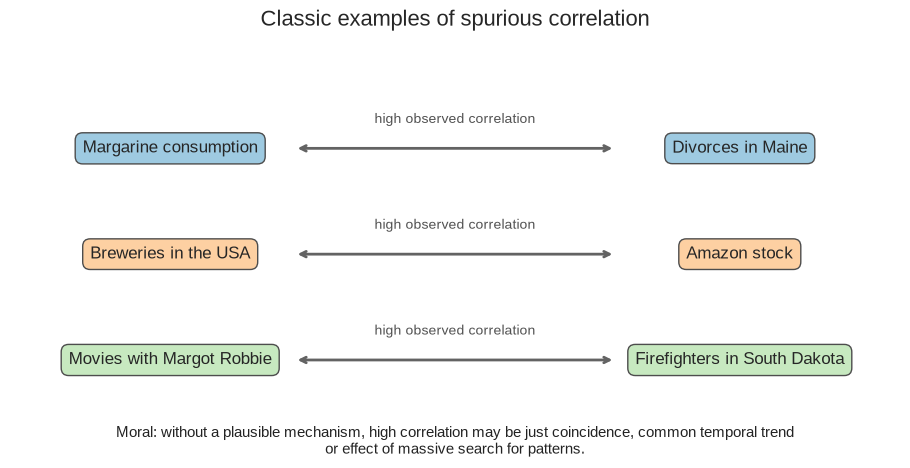

In [7]:
fig, ax = plt.subplots(figsize=(9.2, 4.8))
ax.axis('off')
ax.set_title('Classic examples of spurious correlation', fontsize=16, pad=18)

boxes = [
    ('Margarine consumption', 'Divorces in Maine', '#9ecae1'),
    ('Breweries in the USA', 'Amazon stock', '#fdd0a2'),
    ('Movies with Margot Robbie', 'Firefighters in South Dakota', '#c7e9c0'),
]

ys = [0.76, 0.50, 0.24]
for (left, right, color), y0 in zip(boxes, ys):
    ax.text(0.18, y0, left, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=0.45', facecolor=color, edgecolor='#4d4d4d'))
    ax.text(0.82, y0, right, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=0.45', facecolor=color, edgecolor='#4d4d4d'))
    ax.annotate('', xy=(0.68, y0), xytext=(0.32, y0),
                arrowprops=dict(arrowstyle='<->', lw=2.0, color='#636363'))
    ax.text(0.50, y0 + 0.055, 'high observed correlation', ha='center', va='bottom', fontsize=10, color='#525252')

ax.text(0.5, 0.04,
        'Moral: without a plausible mechanism, high correlation may be just coincidence, common temporal trend\nor effect of massive search for patterns.',
        ha='center', va='center', fontsize=11, color='#222222')

fig.tight_layout()
plt.show()


These examples are useful because they train the critical eye. A high coefficient may arise from a shared temporal trend, a small number of observations, axes that exaggerate the effect, or confounding variables.


### Simpson's paradox

Simpson's paradox occurs when a trend observed within all subgroups disappears or reverses after the data are aggregated.

Didactically, the best way to read this phenomenon is to separate two questions:

- What happens when we compare cases under the same condition?
- What happens when we mix conditions with different difficulties?

In the example below, the context variable will be the noise level of an electronic test bench.


In [8]:
scenarios = {
    'Low noise': {'A': (91, 100), 'B': (228, 260)},
    'High noise': {'A': (59, 100), 'B': (21, 40)},
}

group_names = list(scenarios.keys())
rates_a = [scenarios[g]['A'][0] / scenarios[g]['A'][1] for g in group_names]
rates_b = [scenarios[g]['B'][0] / scenarios[g]['B'][1] for g in group_names]

total_a = sum(scenarios[g]['A'][0] for g in group_names) / sum(scenarios[g]['A'][1] for g in group_names)
total_b = sum(scenarios[g]['B'][0] for g in group_names) / sum(scenarios[g]['B'][1] for g in group_names)

print('Rates by scenario:')
for name, rate_a, rate_b in zip(group_names, rates_a, rates_b):
    print(f'{name}: A = {rate_a:.3f}, B = {rate_b:.3f}')
print(f'Aggregate rate A: {total_a:.3f}')
print(f'Aggregate rate B: {total_b:.3f}')


Rates by scenario:
Low noise: A = 0.910, B = 0.877
High noise: A = 0.590, B = 0.525
Aggregate rate A: 0.750
Aggregate rate B: 0.830


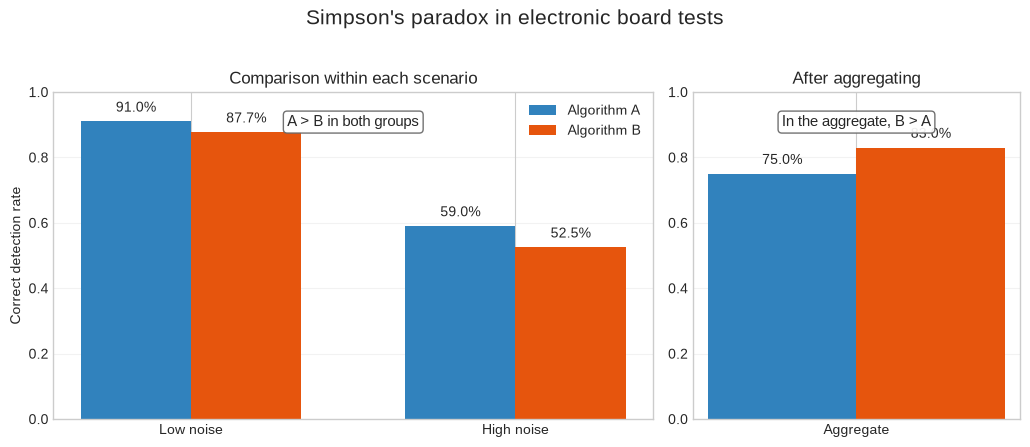

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.3), gridspec_kw={'width_ratios': [2.2, 1.2]})
width = 0.34
group_pos = np.arange(len(group_names))

axes[0].bar(group_pos - width/2, rates_a, width, label='Algorithm A', color='#3182bd')
axes[0].bar(group_pos + width/2, rates_b, width, label='Algorithm B', color='#e6550d')
axes[0].set_xticks(group_pos)
axes[0].set_xticklabels(group_names)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_ylabel('Correct detection rate')
axes[0].set_title('Comparison within each scenario')
axes[0].legend(frameon=False, loc='upper right')
axes[0].grid(axis='y', alpha=0.25)

for i, (ta, tb) in enumerate(zip(rates_a, rates_b)):
    axes[0].text(i - width/2, ta + 0.03, f'{100*ta:.1f}%', ha='center', fontsize=10)
    axes[0].text(i + width/2, tb + 0.03, f'{100*tb:.1f}%', ha='center', fontsize=10)

axes[0].text(0.5, 0.93, 'A > B in both groups', transform=axes[0].transAxes,
             ha='center', va='top', fontsize=11,
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#666666', alpha=0.92))

axes[1].bar([0 - width/2], [total_a], width, color='#3182bd')
axes[1].bar([0 + width/2], [total_b], width, color='#e6550d')
axes[1].set_xticks([0])
axes[1].set_xticklabels(['Aggregate'])
axes[1].set_ylim(0.0, 1.0)
axes[1].set_title('After aggregating')
axes[1].grid(axis='y', alpha=0.25)
axes[1].text(-width/2, total_a + 0.03, f'{100*total_a:.1f}%', ha='center', fontsize=10)
axes[1].text(width/2, total_b + 0.03, f'{100*total_b:.1f}%', ha='center', fontsize=10)
axes[1].text(0.5, 0.93, 'In the aggregate, B > A', transform=axes[1].transAxes,
             ha='center', va='top', fontsize=11,
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#666666', alpha=0.92))

fig.suptitle("Simpson's paradox in electronic board tests", fontsize=15, y=1.03)
fig.tight_layout()
plt.show()


The correct interpretation is this:

- If the question is which algorithm works better under the same noise condition, we must compare row by row.
- In these fair comparisons, algorithm A is better in both scenarios.
- The reversal appears because algorithm B concentrates many more tests in the easy, low-noise scenario.
- Thus, the aggregate rate does not summarize only performance: it also incorporates the unequal distribution between easy and difficult cases.

### Where this appears in Machine Learning

In ML, the same problem arises when we evaluate models only by a global metric, such as total accuracy. A model may look superior because it received more examples of an easy class, of a less noisy batch, or of a majority subgroup.

Therefore, in classification and automatic inspection problems, it is good practice to report metrics by subgroup, by class, and by operating condition.


## 2. Probability


### Conditional probability

Let us simulate the problem: what is the probability that the two dice show the same value, given that the sum was 8?


In [10]:
n = 1_000_000
evens = [(random.randint(1, 6), random.randint(1, 6)) for _ in range(n)]

sum_eight = [p for p in evens if sum(p) == 8]
matching_rolls = [p for p in sum_eight if p[0] == p[1]]


simulation_fraction = len(matching_rolls) / len(sum_eight)
print('Simulation estimate:', round(simulation_fraction, 4))
print('Expected theoretical value:', 1/5)

results = ['different', 'equal']
counts = [len(sum_eight) - len(matching_rolls), len(matching_rolls)]


Simulation estimate: 0.2008
Expected theoretical value: 0.2


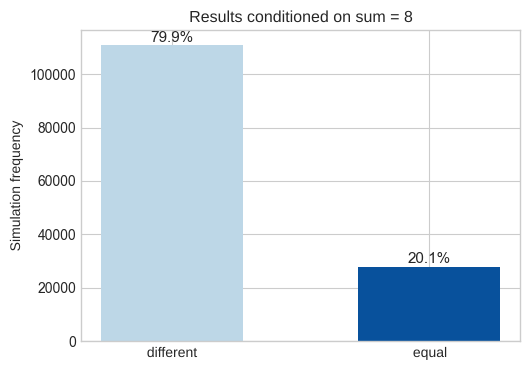

In [11]:
fig, ax = plt.subplots(figsize=(5.4, 3.8))
bars = ax.bar(results, counts, color=['#bdd7e7', '#08519c'], width=0.55)
proportions = [c / sum(counts) for c in counts]
for bar, prop in zip(bars, proportions):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 150,
            f'{prop:.1%}', ha='center', va='bottom', fontsize=11)
ax.set_title('Results conditioned on sum = 8')
ax.set_ylabel('Frequency in the simulation')
fig.tight_layout()
plt.show()


The conditioned event reduces the sample space. After this reduction, only a small part of the remaining cases corresponds to equal dice.


### Bayes' theorem

We will use the same scenario as in the presentation: an automatic test detects defects in boards.


In [12]:
base_rate = 0.02
sensitivity = 0.95
false_positive_rate = 0.04

numerator = sensitivity * base_rate
denominator = numerator + false_positive_rate * (1 - base_rate)
posterior = numerator / denominator

print('P(defective | positive) =', round(posterior, 4))

n_boards = 200000
defective_boards = np.random.rand(n_boards) < base_rate
positive_test = np.where(
    defective_boards,
    np.random.rand(n_boards) < sensitivity,
    np.random.rand(n_boards) < false_positive_rate
)

true_positives = np.sum(defective_boards & positive_test)
false_positives = np.sum((~defective_boards) & positive_test)
print('Simulation:', round(true_positives / (true_positives + false_positives), 4))


P(defective | positive) = 0.3265
Simulation: 0.3226


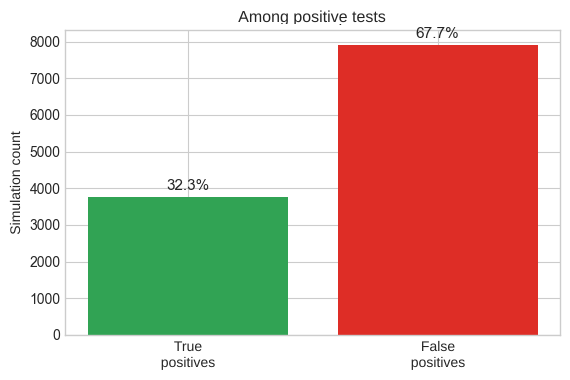

In [13]:
fig, ax = plt.subplots(figsize=(5.8, 3.9))
ax.bar(['True\npositives', 'False\npositives'],
       [true_positives, false_positives],
       color=['#31a354', '#de2d26'])
total_pos = true_positives + false_positives
ax.text(0, true_positives + 180, f'{true_positives/total_pos:.1%}', ha='center', fontsize=11)
ax.text(1, false_positives + 180, f'{false_positives/total_pos:.1%}', ha='center', fontsize=11)
ax.set_title('Among positive tests')
ax.set_ylabel('Count in the simulation')
fig.tight_layout()
plt.show()


The low base rate makes a difference: even a good test still produces many positives on good boards, because they are the majority.


### Random variables, continuous distributions, and normal

A normal curve is useful for modeling measurement errors and noise. Let us compare two curves with the same mean and different standard deviations.


### Cumulative distribution function (CDF)

Besides the density, it is important to know the cumulative distribution function:

\[
F(x) = P(X \leq x)
\]

The CDF informs how much probability has already been accumulated up to a point. In continuous variables, it grows from 0 to 1 and corresponds to the accumulated area under the density curve.


In [14]:
from statistics import NormalDist

standard_normal = NormalDist(mu=0, sigma=1)
cdf_value = standard_normal.cdf(0)
print('P(Z <= 1.0) =', cdf_value)

P(Z <= 1.0) = 0.5


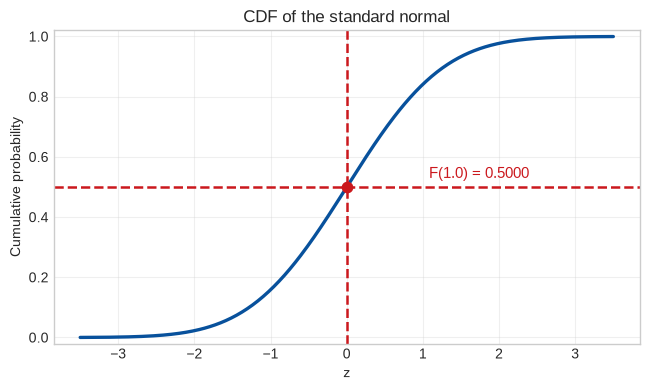

In [15]:
x_cdf = np.linspace(-3.5, 3.5, 400)
cdf_vals = np.array([standard_normal.cdf(v) for v in x_cdf])

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.plot(x_cdf, cdf_vals, color='#08519c', linewidth=2.4)
ax.axvline(0, color='#cb181d', linestyle='--', linewidth=1.8)
ax.axhline(cdf_value, color='#cb181d', linestyle='--', linewidth=1.8)
ax.scatter([0], [cdf_value], color='#cb181d', s=55, zorder=3)
ax.text(1.08, cdf_value + 0.03, f'F(1.0) = {cdf_value:.4f}', color='#cb181d', fontsize=11)
ax.set_title('CDF of the standard normal')
ax.set_xlabel('z')
ax.set_ylabel('Cumulative probability')
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


This value is approximately 0.8413. Therefore, in the standard normal, there is about 84.13% probability of observing a value less than or equal to 1.


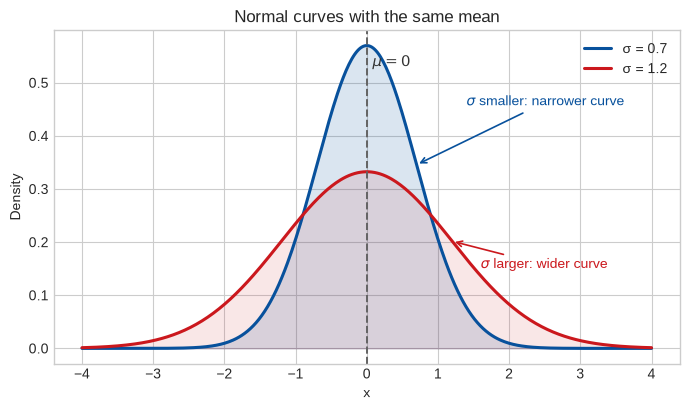

In [16]:
def normal_density(x, mu, sigma):
    factor = 1 / (sigma * math.sqrt(2 * math.pi))
    exponent = -0.5 * ((x - mu) / sigma) ** 2
    return factor * np.exp(exponent)

x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7.0, 4.2))
y1 = normal_density(x, 0, 0.7)
y2 = normal_density(x, 0, 1.2)
ax.plot(x, y1, label='σ = 0.7', linewidth=2.2, color='#08519c')
ax.plot(x, y2, label='σ = 1.2', linewidth=2.2, color='#cb181d')
ax.fill_between(x, y1, alpha=0.15, color='#08519c')
ax.fill_between(x, y2, alpha=0.10, color='#cb181d')
ax.axvline(0, color='#636363', linestyle='--', linewidth=1.4)
ax.text(0.08, max(y1.max(), y2.max()) * 0.93, '$\\mu = 0$', color='#333333', fontsize=11)
ax.annotate('$\\sigma$ smaller: narrower curve', xy=(0.7, normal_density(0.7, 0, 0.7)),
            xytext=(1.4, y1.max() * 0.8), arrowprops=dict(arrowstyle='->', color='#08519c', lw=1.2),
            color='#08519c', fontsize=10)
ax.annotate('$\\sigma$ larger: wider curve', xy=(1.2, normal_density(1.2, 0, 1.2)),
            xytext=(1.6, y2.max() * 0.45), arrowprops=dict(arrowstyle='->', color='#cb181d', lw=1.2),
            color='#cb181d', fontsize=10)
ax.set_title('Normal curves with the same mean')
ax.set_xlabel('x')
ax.set_ylabel('Density')
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
plt.show()


Curves with larger standard deviation are more spread out. In measurements, this means greater uncertainty and greater variation of the observed values.


### Central limit theorem

Now we compare an asymmetric original distribution with the distribution of the means of several samples.


In [17]:
original_samples = np.random.exponential(scale=5, size=50_000)
means = np.array(
    [np.mean(np.random.exponential(scale=5, size=300)) for _ in range(1000)]
                 )

print('Mean of the original data:', round(original_samples.mean(), 4))
print('Mean of the sample means:', round(means.mean(), 4))
print('Standard deviation of the original data:', round(original_samples.std(), 4))
print('Standard deviation of the sample means:', round(means.std(), 4))


Mean of the original data: 4.9764
Mean of the sample means: 5.0086
Standard deviation of the original data: 4.9919
Standard deviation of the sample means: 0.2993


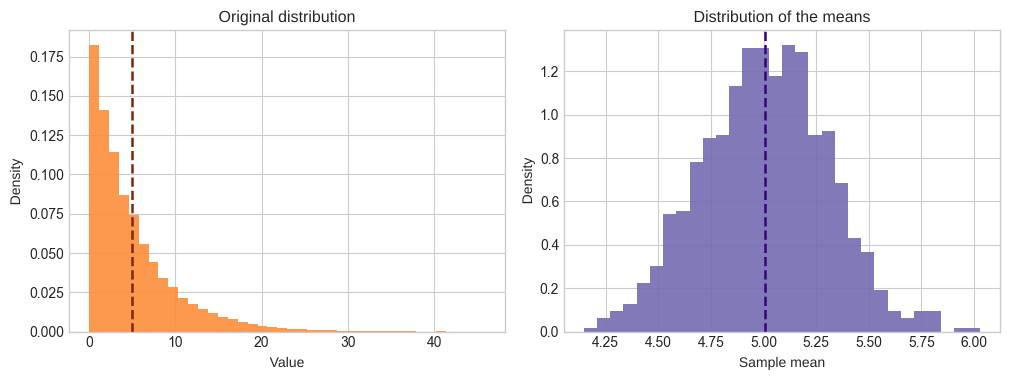

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.9))

axes[0].hist(original_samples, bins=40, color='#fd8d3c', alpha=0.9, density=True)
axes[0].set_title('Original distribution')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')
axes[0].axvline(original_samples.mean(), color='#7f2704', linestyle='--', linewidth=1.8)

axes[1].hist(means, bins=30, color='#756bb1', alpha=0.9, density=True)
axes[1].set_title('Distribution of the means')
axes[1].set_xlabel('Sample mean')
axes[1].set_ylabel('Density')
axes[1].axvline(means.mean(), color='#3f007d', linestyle='--', linewidth=1.8)

fig.tight_layout()
plt.show()


The original distribution is quite asymmetric. The distribution of the means is more concentrated and closer to the normal shape, illustrating the central limit theorem.


## Additional materials

Suggestions to continue studying:
- change the datasets and observe the effect on the mean, median, and standard deviation;
- create your own examples of spurious or nonlinear correlation;
- vary the base rate in the Bayes example and compare the results;
- repeat the central limit simulation with uniform, binomial, and lognormal distributions;
- review chapters 5 and 6 of *Data Science do Zero* with the notebook at hand.
